In [4]:
import json
from datetime import datetime

import numpy as np
import qiskit as qk
import tn_simulate_qpt
import noise_channels
import qiskit.qasm2 as qasm2

### Simulate experimentms with Tensor Network sampler

          
q_0: ──■──
     ┌─┴─┐
q_1: ┤ X ├
     └───┘
q_2: ──■──
     ┌─┴─┐
q_3: ┤ X ├
     └───┘
q_4: ──■──
     ┌─┴─┐
q_5: ┤ X ├
     └───┘
q_6: ──■──
     ┌─┴─┐
q_7: ┤ X ├
     └───┘
q_8: ──■──
     ┌─┴─┐
q_9: ┤ X ├
     └───┘
-> UNIFORM GLOBAL STRATEGY WITH REPEATED SETTINGS.
Total number of shots = 1000000 (number of settings = 1000, shots per setting = 1000


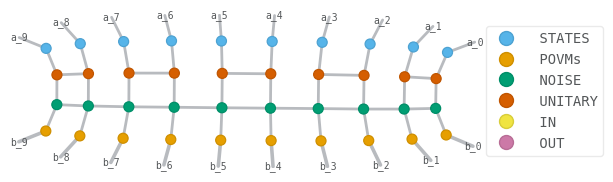

100%|██████████| 1000000/1000000 [23:16<00:00, 715.97it/s]


AttributeError: 'QuantumCircuit' object has no attribute 'qasm'

In [ ]:
seed = 231
np.random.seed(seed)

######################################
# SELECT THE UNITARY OPERATION
######################################
num_qubits = 10
qc = qk.QuantumCircuit(num_qubits)
qc.cx(0,1)
qc.cx(2,3)
qc.cx(4,5)
qc.cx(6,7)
qc.cx(8,9)
#qc.cx(10,11)
#qc.cx(12,13)
#qc.cx(14,15)
print(qc)

######################################
# SELECT THE NOISE CHANNEL
######################################
#noise_str = 'even_depol1_odd_depol05'
#noise_str = 'identity'
noise_str = 'noise_model_coef_ibm_hanoi_10qchain25_dd_inst1_layer0_unit_100_100s'
noise_mpo = noise_channels.select_noise_channel(noise_str, num_qubits, tensor_type = 'mpo')
        
######################################
# SELECT NUMBER OF SHOTS AND NAMEFILE
######################################
num_settings = 1000
shots_per_setting = 1000
num_shots = num_settings * shots_per_setting 
      
######################################
# SELECT INPUT STATES AND MEAS BASIS
######################################
input_states = 'sic_states' # or 'sic_states'

if input_states == 'oc_pauli_eigenstates':
    num_states = 6

elif input_states == 'sic_states':
    num_states = 4

else:
    raise ValueError(f"Type of input states {input_states} not available.")

strategy = 'global_repeated'

if strategy == 'local':
    print("-> UNIFORM LOCAL STRATEGY.")
    locality = 2
    num_shots = int(shots_per_setting * (num_states * 3) ** locality) # 3 are the three possible measurement basis
    preps_and_meas = tn_simulate_qpt.local_preps_and_meas(num_qubits, locality=locality, num_shots=num_shots, num_states=num_states)
    num_shots = len(preps_and_meas)
    print(f"Total number of shots = {num_shots} (number of settings = {num_shots // shots_per_setting}, shots per setting = {shots_per_setting}")

elif strategy == 'global':
    print("-> UNIFORM GLOBAL STRATEGY.")
    locality = ''
    shots_per_setting = 1    
    preps_and_meas = None

elif strategy == 'global_repeated':
    print("-> UNIFORM GLOBAL STRATEGY WITH REPEATED SETTINGS.")
    locality = ''
    preps_and_meas = [[(np.random.randint(0, num_states, size=num_qubits).tolist(), np.random.randint(0, 3, size=num_qubits).tolist()), ] * shots_per_setting for _ in range(num_shots // shots_per_setting)]
    preps_and_meas = tn_simulate_qpt.flatten_list(preps_and_meas)
    num_shots = len(preps_and_meas)
    print(f"Total number of shots = {num_shots} (number of settings = {num_shots // shots_per_setting}, shots per setting = {shots_per_setting}")

else:
    raise TypeError(f"Strategy {strategy} not implemented.")

######################################
# BUILD THE QPT MPO
######################################
qpt_mpo, states, povms = tn_simulate_qpt.build_qpt_mpo(qc_unitary = qc, noise_mpo = noise_mpo, input_states=input_states)
qpt_mpo.draw(color = ['STATES', 'POVMs', 'NOISE', 'UNITARY', 'IN', 'OUT'], show_tags = False)
        
######################################
# SIMULATE EXPERIMENTS
######################################
experiments = tn_simulate_qpt.simulate_experiments(qpt_mpo, num_shots = num_shots, preps_and_meas = preps_and_meas, joblib_workers = - 1)

######################################
# SAVE RESULTS
######################################
res = {'qc': qasm2.dumps(qc), 
       'noise': noise_str,
       'locality': locality,
       'num_shots': num_shots,
       'num_settings': num_shots // shots_per_setting,
       'shots_per_setting': shots_per_setting,
       'strategy': strategy,
       'states': states.astype('str').tolist(),
       'povms': povms.astype('str').tolist(),
       'counts': experiments}

save_results = True
if save_results:
    file_folder = ''#'simulated_data/'
    file_name = f'cxeven_nq{num_qubits}_{noise_str}_ns{num_shots}_{strategy}{locality}_{input_states}_TEST'
    today = datetime.today().strftime('%Y-%m-%d')
    with open(file_folder + file_name + '_' + today + '.json', 'w') as file:
        json.dump(res, file, indent = 4)

In [5]:
######################################
# SAVE RESULTS
######################################
res = {'qc': qasm2.dumps(qc), 
       'noise': noise_str,
       'locality': locality,
       'num_shots': num_shots,
       'num_settings': num_shots // shots_per_setting,
       'shots_per_setting': shots_per_setting,
       'strategy': strategy,
       'states': states.astype('str').tolist(),
       'povms': povms.astype('str').tolist(),
       'counts': experiments}

save_results = True
if save_results:
    file_folder = ''#'simulated_data/'
    file_name = f'cxeven_nq{num_qubits}_{noise_str}_ns{num_shots}_{strategy}{locality}_{input_states}_TEST'
    today = datetime.today().strftime('%Y-%m-%d')
    with open(file_folder + file_name + '_' + today + '.json', 'w') as file:
        json.dump(res, file, indent = 4)

In [6]:
num_qubits = 10 
locality = 2
num_shots = 1000
shots_per_setting = 1000
num_states = 4
preps_and_meas = tn_simulate_qpt.local_preps_and_meas(num_qubits, locality=locality, num_shots=num_shots, num_states=num_states)

--> Selected 16 input states and 9 measurement basis.



In [7]:
num_shots = 1000
shots_per_setting = 10
num_qubits = 10 
num_states = 4
a = [[(np.random.randint(0, num_states, size=num_qubits).tolist(), np.random.randint(0, 3, size=num_qubits).tolist()), ] * shots_per_setting for _ in range(num_shots)]
a = tn_simulate_qpt.flatten_list(a)
a[:4]

[([1, 1, 1, 0, 2, 3, 3, 1, 2, 3], [1, 0, 1, 2, 2, 1, 2, 2, 1, 1]),
 ([1, 1, 1, 0, 2, 3, 3, 1, 2, 3], [1, 0, 1, 2, 2, 1, 2, 2, 1, 1]),
 ([1, 1, 1, 0, 2, 3, 3, 1, 2, 3], [1, 0, 1, 2, 2, 1, 2, 2, 1, 1]),
 ([1, 1, 1, 0, 2, 3, 3, 1, 2, 3], [1, 0, 1, 2, 2, 1, 2, 2, 1, 1])]

In [8]:
if 10 % 10 == 0:
    print("Carola")

Carola


In [9]:
import lpdo_utils
import matplotlib.pyplot as plt

In [10]:
qc1 = qk.QuantumCircuit(2)
qc1.h(0)
print(qc1)

qc2 = qk.QuantumCircuit(2)
qc2.cx(0,1)
print(qc2)

qc = qk.QuantumCircuit(2)
qc.h(0)
qc.cx(0,1)
qc.draw()

     ┌───┐
q_0: ┤ H ├
     └───┘
q_1: ─────
          
          
q_0: ──■──
     ┌─┴─┐
q_1: ┤ X ├
     └───┘


┌───┐     
q_0: ┤ H ├──■──
     └───┘┌─┴─┐
q_1: ─────┤ X ├
          └───┘

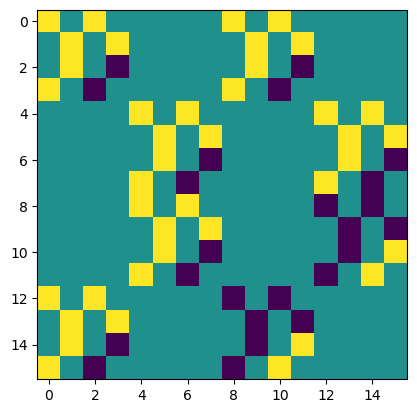

In [11]:
from qiskit.quantum_info import SuperOp
qcinv = qk.QuantumCircuit(2)
qcinv.h(1)
qcinv.cx(1,0)
plt.imshow(SuperOp(qcinv).data.real)

In [12]:
def lpdo_to_superop(lpdo):
    num_qubits = lpdo.L
    left_inds  = [lpdo.lower_outer_ind_id.format(_) for _ in range(num_qubits)] + [lpdo.upper_outer_ind_id.format(_) for _ in range(num_qubits)]
    right_inds = [lpdo.lower_inner_ind_id.format(_) for _ in range(num_qubits)] + [lpdo.upper_inner_ind_id.format(_) for _ in range(num_qubits)]
    return lpdo.contract().to_dense(left_inds, right_inds)

l = lpdo_utils.build_lpdo(tn_data=qc)
plt.imshow(lpdo_to_superop(l).real)

AttributeError: 'LPDOSuperOperator1D' object has no attribute 'lower_outer_ind_id'

In [ ]:
l1 = lpdo_utils.build_lpdo(tn_data=qc1)
l2 = lpdo_utils.build_lpdo(tn_data=qc2)
ltot = lpdo_utils.compose_lpdos(l2, l1)
plt.imshow(lpdo_to_superop(ltot).real)

In [ ]:
opt_lpdo = lpdo_utils.build_lpdo(tn_data = res['params'][-1].values())

left_inds  = [f'bn{_}' for _ in range(num_qubits)] + [f'kn{_}' for _ in range(num_qubits)]
right_inds = [f'b{_}' for _ in range(num_qubits)] + [f'k{_}' for _ in range(num_qubits)]
opt_superop = opt_lpdo.contract().to_dense(left_inds, right_inds)

#true_superop = true_lpdo.contract().to_dense(left_inds, right_inds)
plt.imshow(opt_superop.real)
plt.colorbar()